In [1]:
import pandas as pd
import seaborn as sns

ValueError: Key backend: 'module://matplotlib_inline.backend_inline' is not a valid value for backend; supported values are ['gtk3agg', 'gtk3cairo', 'gtk4agg', 'gtk4cairo', 'macosx', 'nbagg', 'notebook', 'qtagg', 'qtcairo', 'qt5agg', 'qt5cairo', 'tkagg', 'tkcairo', 'webagg', 'wx', 'wxagg', 'wxcairo', 'agg', 'cairo', 'pdf', 'pgf', 'ps', 'svg', 'template']

In [3]:
titanic = pd.read_csv('train.csv')

In [4]:
df = sns.load_dataset('tips')

In [5]:
flights = sns.load_dataset('flights')

In [6]:
iris  = sns.load_dataset('iris')

In [7]:
flights.info()

<class 'pandas.DataFrame'>
RangeIndex: 144 entries, 0 to 143
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   year        144 non-null    int64   
 1   month       144 non-null    category
 2   passengers  144 non-null    int64   
dtypes: category(1), int64(2)
memory usage: 2.9 KB


## 1. Scatterplot (Numerical - Numerical)

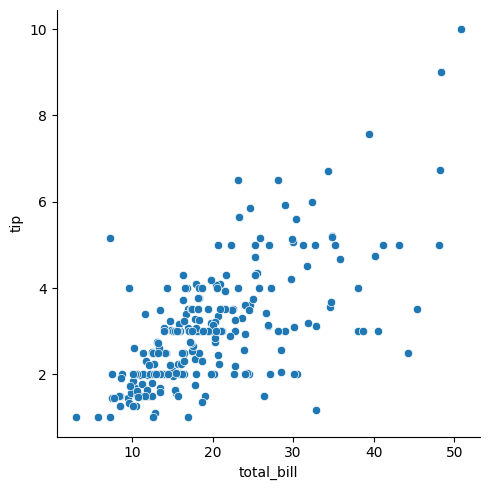

In [8]:
# we will use tips dataset for the same
# Bivariate  Analysis
sns.relplot(data=df, x='total_bill',y='tip', kind='scatter')

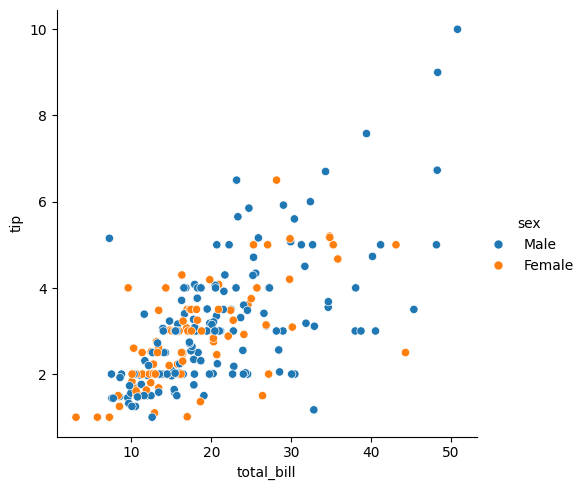

In [9]:
# Multivariate Analysis (Analysis on two or more column)
sns.relplot(data=df, x='total_bill',y='tip', kind='scatter', hue='sex')


<Axes: xlabel='total_bill', ylabel='tip'>

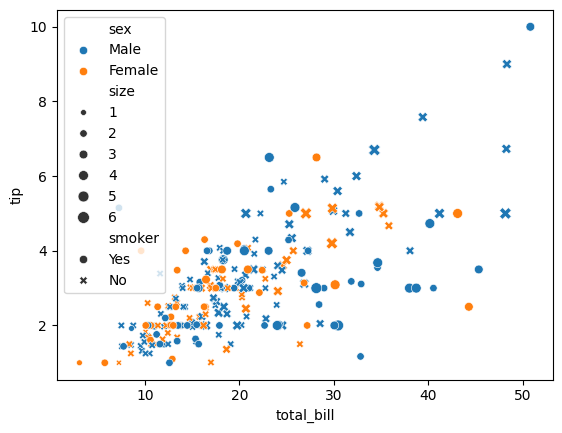

In [10]:
sns.scatterplot(data=df, x='total_bill',y='tip', hue='sex',style='smoker',size='size')


## 2. Barplot (Numerical - Catagorical)

<Axes: xlabel='Pclass', ylabel='Age'>

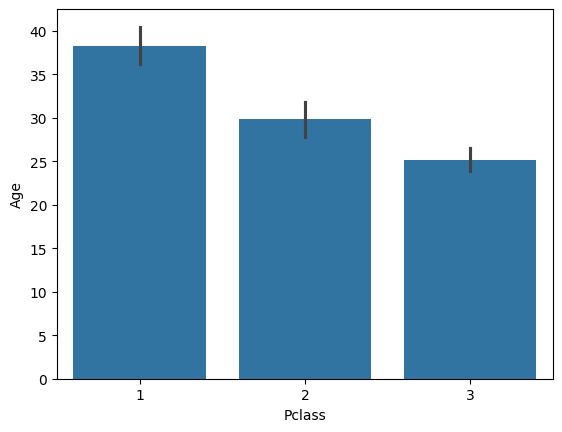

In [11]:
sns.barplot(data=titanic, y='Age', x='Pclass')
# The Black mark shows confidence interval

<Axes: xlabel='Pclass', ylabel='Fare'>

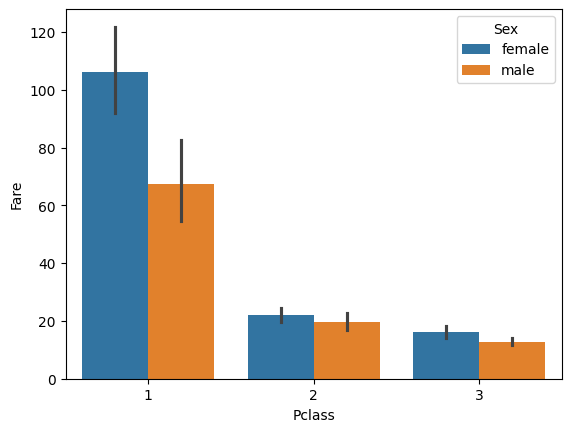

In [12]:
sns.barplot(data=titanic, x='Pclass', y='Fare',hue='Sex')

## 3. BoxPlot (Numerical - Categorical)

<Axes: xlabel='Sex', ylabel='Age'>

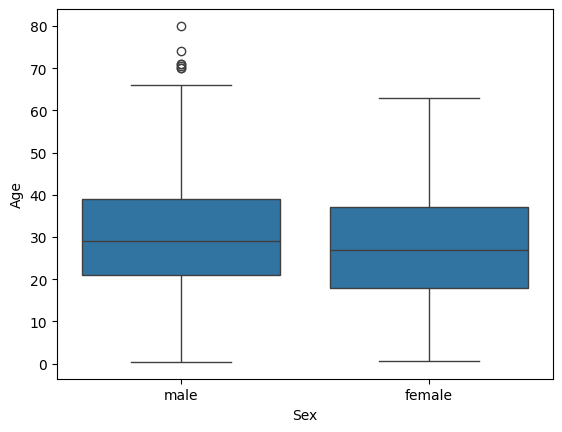

In [13]:
sns.boxplot(data=titanic, x='Sex', y='Age')

### 4. Displot (Numnerical-Categorical)

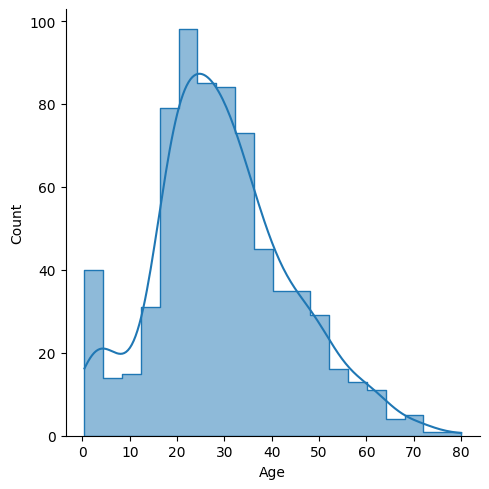

In [14]:
sns.displot(data=titanic, x='Age', kde=True, element='step')

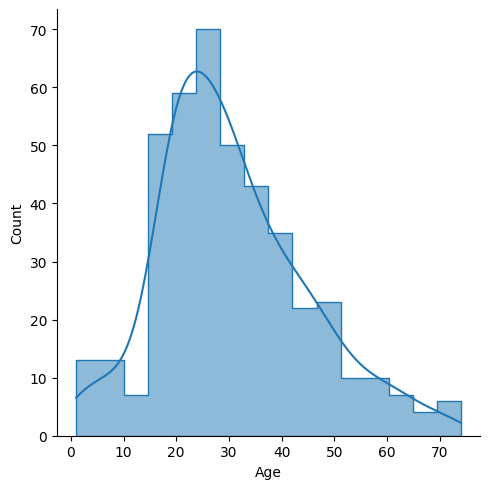

In [15]:
sns.displot(titanic[titanic['Survived'] == 0]['Age'], kde=True, element='step')


<Axes: xlabel='Age', ylabel='Density'>

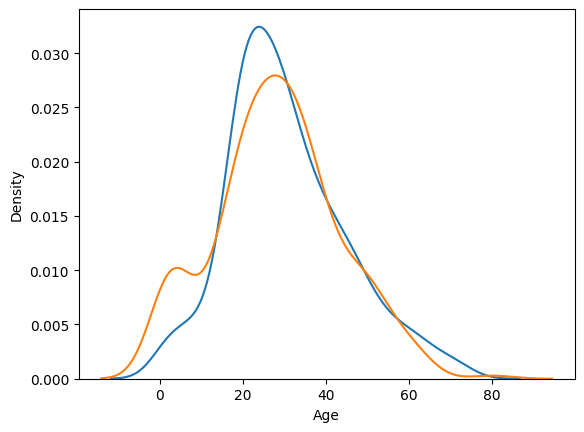

In [17]:
sns.kdeplot(titanic[titanic['Survived']==0]['Age'])
sns.kdeplot(titanic[titanic['Survived']==1]['Age'])


<Axes: xlabel='Age', ylabel='Density'>

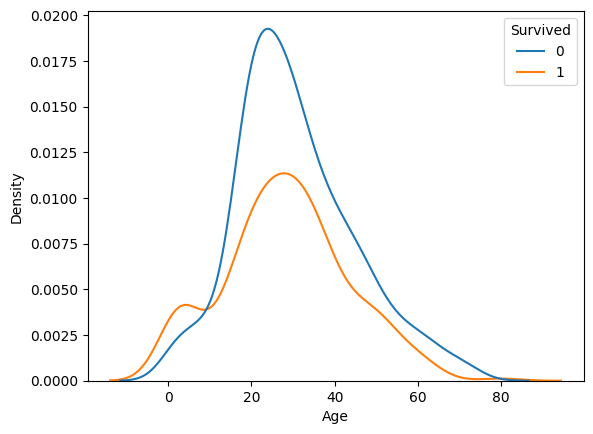

In [20]:
sns.kdeplot(data=titanic, x='Age', hue='Survived')

## 5. HeatMap (Categorical - Categorical)

In [21]:
titanic.head(3)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S


In [23]:
# Now we will check between pclass and survivor both are categorical data
pd.crosstab(titanic['Pclass'], titanic['Survived'])

Survived,0,1
Pclass,,
1,80,136
2,97,87
3,372,119


<Axes: xlabel='Survived', ylabel='Pclass'>

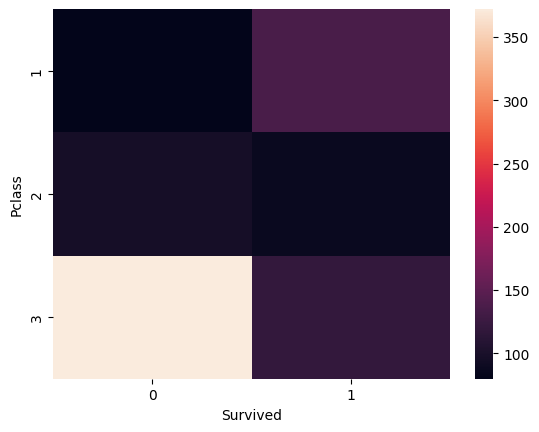

In [24]:
sns.heatmap(pd.crosstab(titanic['Pclass'], titanic['Survived']))

In [27]:
titanic.groupby('Pclass')['Survived'].mean() * 100

Pclass
1    62.962963
2    47.282609
3    24.236253
Name: Survived, dtype: float64

In [28]:
titanic.groupby('Sex')['Survived'].mean() * 100


Sex
female    74.203822
male      18.890815
Name: Survived, dtype: float64

<Axes: xlabel='Pclass'>

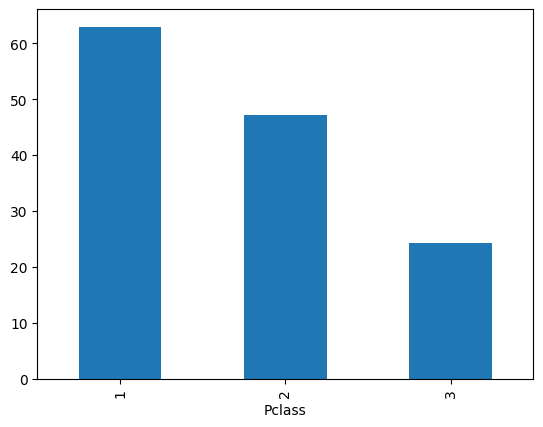

In [29]:
(titanic.groupby('Pclass')['Survived'].mean() * 100).plot(kind='bar')


### 6. ClusterMap (Categorical - Categorical)

In [34]:
pd.crosstab(titanic['SibSp'],titanic['Survived'])

Survived,0,1
SibSp,,
0,398,210
1,97,112
2,15,13
3,12,4
4,15,3
5,5,0
8,7,0


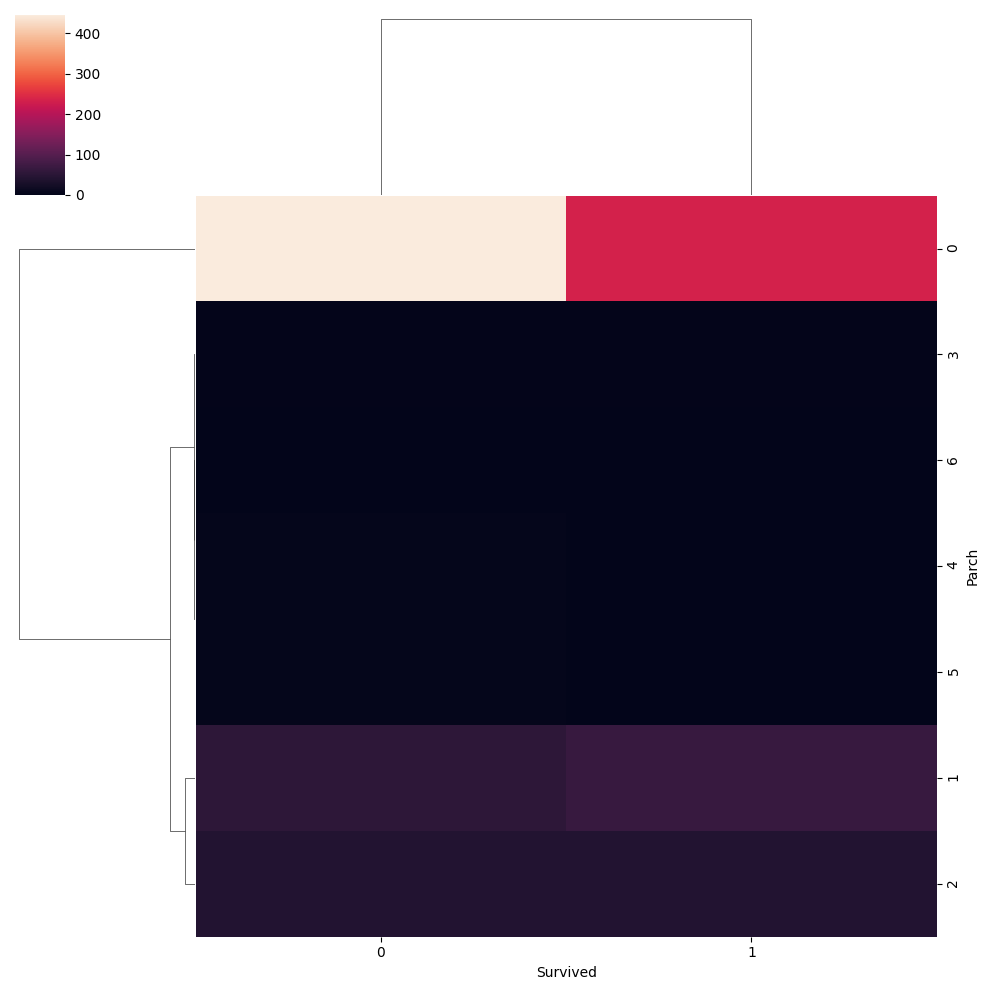

In [36]:
sns.clustermap(pd.crosstab(titanic['Parch'],titanic['Survived']))


### 7. PairPlot

In [37]:
iris.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


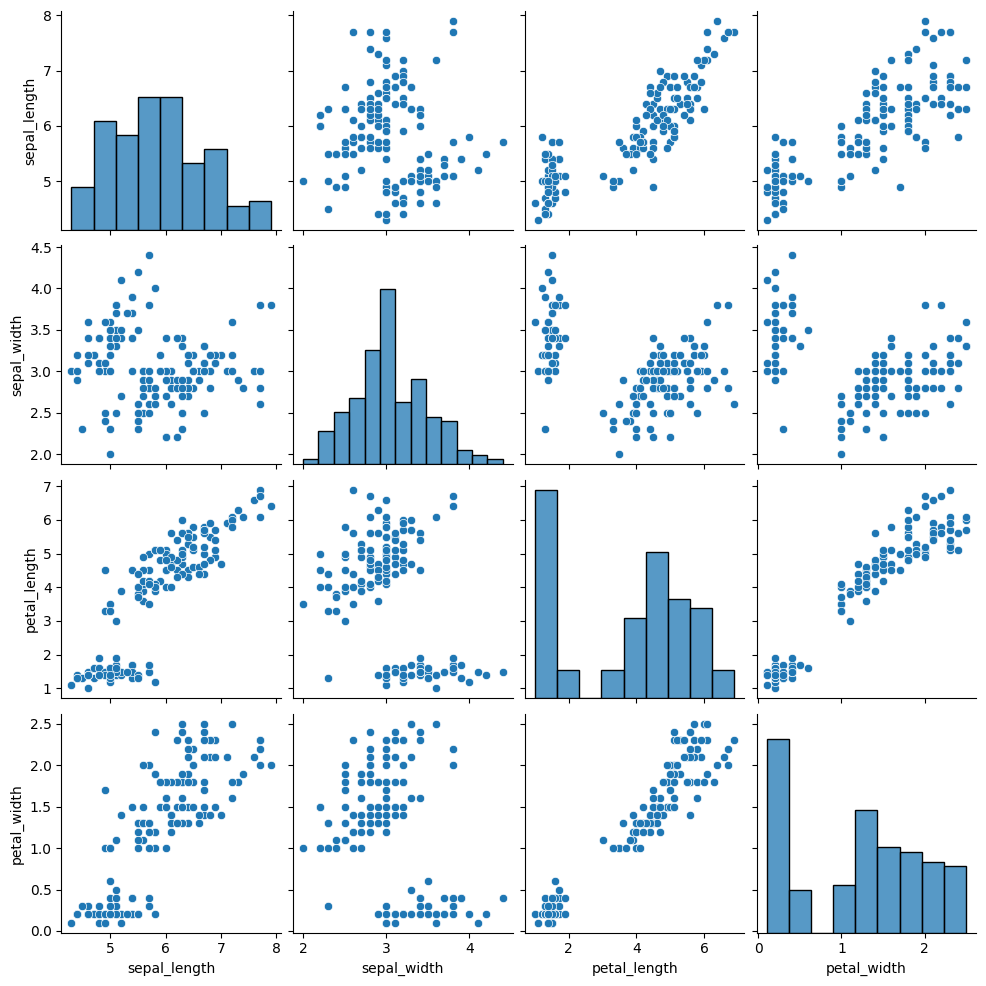

In [38]:
sns.pairplot(iris)

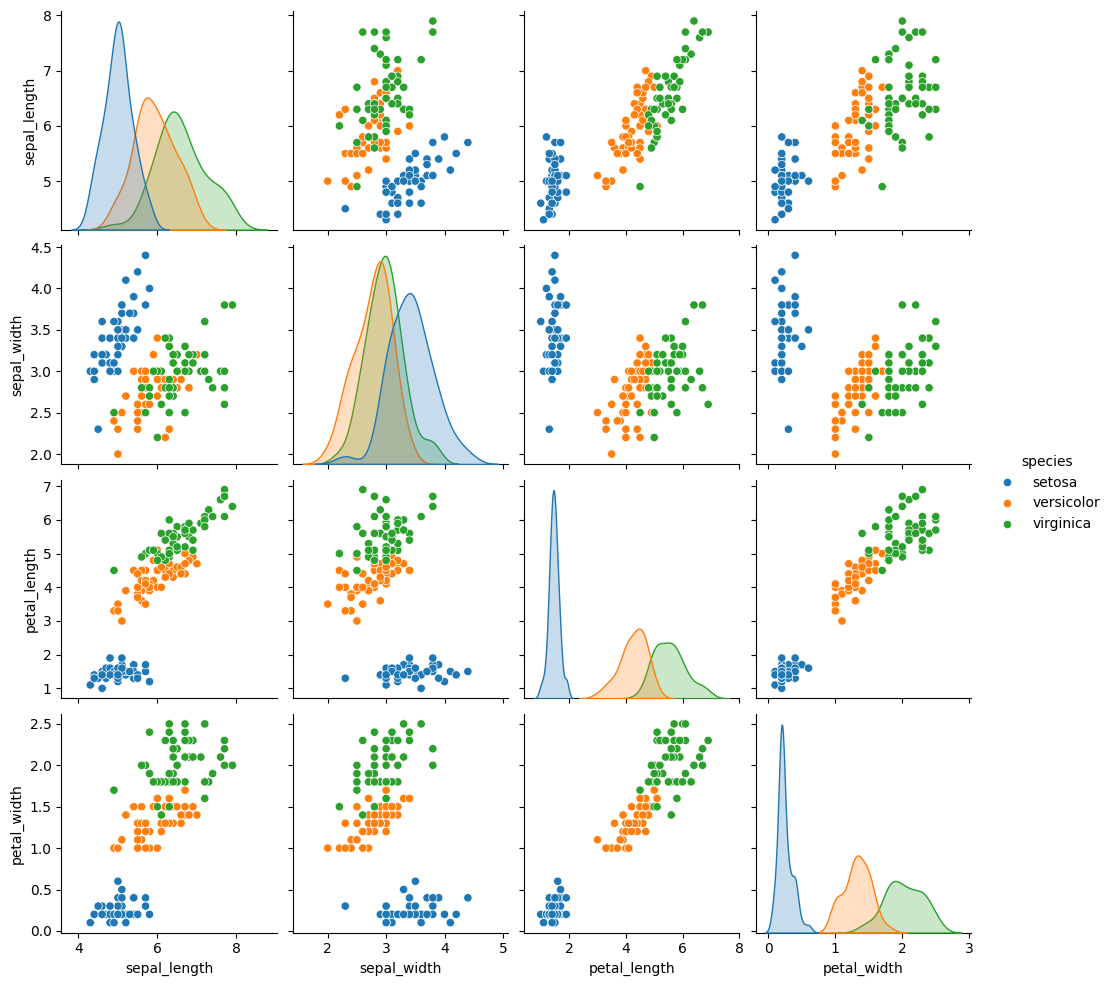

In [39]:
sns.pairplot(iris, hue='species')

### 8. LinePlot (Numerical - Numerical)

In [41]:
# We can use line plot where we have like time based number or time related quanities (Date, Year, Month)
flights.head()


,year,month,passengers
0,1949,Jan,112
1,1949,Feb,118
2,1949,Mar,132
3,1949,Apr,129
4,1949,May,121


In [46]:
# for no. of passengers every year
new = flights.groupby('year')['passengers'].sum().reset_index()
new


,year,passengers
0,1949,1520
1,1950,1676
2,1951,2042
3,1952,2364
4,1953,2700
5,1954,2867
6,1955,3408
7,1956,3939
8,1957,4421
9,1958,4572


<Axes: xlabel='year', ylabel='passengers'>

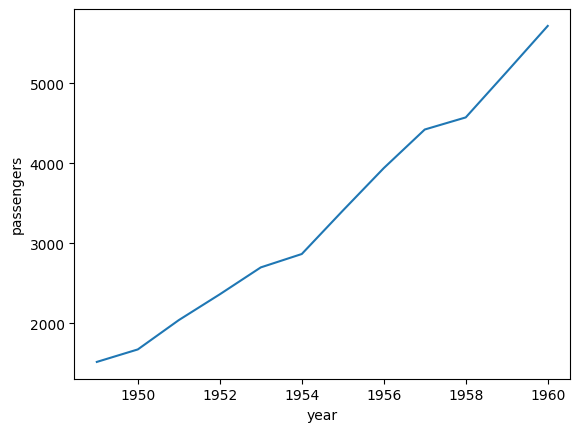

In [49]:
sns.lineplot(data=new, x='year', y='passengers') # time based quantity should be passed in x-axis

In [50]:
flights

,year,month,passengers
0,1949,Jan,112
1,1949,Feb,118
2,1949,Mar,132
3,1949,Apr,129
4,1949,May,121
...,...,...,...
139,1960,Aug,606
140,1960,Sep,508
141,1960,Oct,461
142,1960,Nov,390


In [53]:
data = flights.pivot_table(values='passengers', index='month', columns='year')
data

year,1949,1950,1951,1952,1953,1954,1955,1956,1957,1958,1959,1960
month,,,,,,,,,,,,
Jan,112.0,115.0,145.0,171.0,196.0,204.0,242.0,284.0,315.0,340.0,360.0,417.0
Feb,118.0,126.0,150.0,180.0,196.0,188.0,233.0,277.0,301.0,318.0,342.0,391.0
Mar,132.0,141.0,178.0,193.0,236.0,235.0,267.0,317.0,356.0,362.0,406.0,419.0
Apr,129.0,135.0,163.0,181.0,235.0,227.0,269.0,313.0,348.0,348.0,396.0,461.0
May,121.0,125.0,172.0,183.0,229.0,234.0,270.0,318.0,355.0,363.0,420.0,472.0
Jun,135.0,149.0,178.0,218.0,243.0,264.0,315.0,374.0,422.0,435.0,472.0,535.0
Jul,148.0,170.0,199.0,230.0,264.0,302.0,364.0,413.0,465.0,491.0,548.0,622.0
Aug,148.0,170.0,199.0,242.0,272.0,293.0,347.0,405.0,467.0,505.0,559.0,606.0
Sep,136.0,158.0,184.0,209.0,237.0,259.0,312.0,355.0,404.0,404.0,463.0,508.0


<Axes: xlabel='year', ylabel='month'>

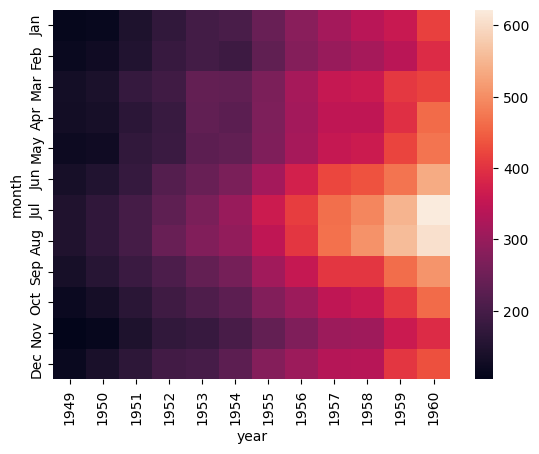

In [54]:
sns.heatmap(data)